# Tutorial 5 -- Adjoint Methods for PDE-Constrained Inverse Problems

**Inverse Study Series | Student-facing notebook | Google Colab / local Python**

**Estimated time:** 45–60 minutes  
**Libraries:** NumPy, SciPy, Matplotlib  
**Prerequisites:** least squares, matrix derivatives, SVD and regularisation (Previous )

## Learning objectives

By the end of this tutorial, you should be able to:

1. Explain why adjoints are useful when an inverse problem has many unknown parameters.
2. Derive a discrete adjoint equation using a Lagrangian.
3. Implement an adjoint gradient for a PDE-constrained objective.
4. Verify the gradient against finite differences (and know what such a check can and cannot catch).
5. Recover an unknown source field from sparse, noisy observations.
6. Explain how regularisation affects reconstruction, and check that your optimiser has actually converged.

> **Core idea:** an adjoint method computes the gradient with respect to *all* parameters using one forward solve and one adjoint solve per objective evaluation, rather than one extra forward solve per parameter. The exact cost depends on the PDE and the solver implementation.

## 1. The inverse problem and its computational challenge

Suppose a physical system is described by a PDE. We can simulate the state, but one field or parameter is unknown. We observe only a limited number of measurements and want to infer that unknown.

A general formulation is

$$
R(u,m)=0,
$$

$$
J(u,m)=\frac12\,\|H(u)-d\|_W^2+\frac{\beta}{2}\,\|Lm\|_2^2 .
$$

Here:

- $u$: state variable, such as temperature or velocity;
- $m$: unknown parameter or source field;
- $R$: discretised (or continuous) governing equation;
- $H$: observation operator;
- $d$: measured data;
- $W$: data-weighting matrix (inverse noise covariance). In this tutorial we take $W=I$, i.e. unweighted least squares;
- $L$: regularisation operator;
- $\beta$: regularisation strength.

The state $u$ depends on $m$ through the governing equation. Changing $m$ therefore changes both the state and the data-misfit term.

### Why not finite-difference every parameter?

If $m$ has $N$ unknown entries, a forward finite-difference gradient needs $N+1$ objective evaluations (one base point plus one per parameter), and a central-difference gradient needs $2N$. Every evaluation contains a PDE solve. An adjoint method instead needs one forward solve and one adjoint solve, regardless of $N$.

We will first derive the method, then test it on a small PDE inverse problem.

## 2. Warm-up: a linear inverse problem

Consider

$$
y=Am,\qquad J(m)=\tfrac12\|Am-d\|_2^2 .
$$

Let $r=Am-d$. Differentiating gives

$$
\nabla_m J=A^T(Am-d)=A^Tr .
$$

The transpose $A^T$ maps a data-space residual back into parameter space. This is the simplest finite-dimensional example of the operation that appears in adjoint methods.

### Run the cell and compare the gradient with a finite difference

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.optimize import minimize


rng_demo = np.random.default_rng(7)

A_demo = rng_demo.normal(size=(30, 12))
m_demo_true = rng_demo.normal(size=12)
d_demo = A_demo @ m_demo_true + 0.02 * rng_demo.normal(size=30)

def linear_objective(m):
    residual = A_demo @ m - d_demo
    J = 0.5 * residual @ residual
    grad = A_demo.T @ residual
    return J, grad

m_test = rng_demo.normal(size=12)
J, grad = linear_objective(m_test)


v_demo = rng_demo.normal(size=12)
h = 1e-6
fd = (linear_objective(m_test + h * v_demo)[0] - linear_objective(m_test - h * v_demo)[0]) / (2 * h)

print(f"Objective J = {J:.6e}")
print(f"Gradient shape = {grad.shape}")
print(f"First five gradient entries = {grad[:5]}")
print(f"Directional derivative: A^T r -> {grad @ v_demo:+.8e} | finite difference -> {fd:+.8e}")

Objective J = 1.448678e+02
Gradient shape = (12,)
First five gradient entries = [ -4.4294998  -17.48418213   8.2094718   -5.19771269  23.65114511]
Directional derivative: A^T r -> +5.45375658e+01 | finite difference -> +5.45375658e+01


## 3. Deriving the discrete adjoint

After spatial discretisation, many PDE constraints can be written abstractly as

$$
R(u,m)=0 .
$$

We seek to minimise $J(u,m)$ subject to this constraint. Introduce a Lagrange multiplier (the **adjoint variable**) $\lambda$:

$$
\mathcal{L}(u,m,\lambda)=J(u,m)-\lambda^T R(u,m).
$$

Write $J_u=\partial J/\partial u$ and $R_u=\partial R/\partial u$ for Jacobians (so $J_u$ is a row vector and $R_u$ is a matrix). The first variation is

$$
\delta\mathcal{L}=J_u\,\delta u+J_m\,\delta m-\lambda^T\big(R_u\,\delta u+R_m\,\delta m\big).
$$

Collect the coefficients multiplying $\delta u$ and $\delta m$:

$$
\delta\mathcal{L}=\big(J_u^T-R_u^T\lambda\big)^T\delta u+\big(J_m^T-R_m^T\lambda\big)^T\delta m .
$$

Choose $\lambda$ so that the coefficient of $\delta u$ vanishes:

$$
\boxed{R_u^T\lambda=J_u^T}\qquad\text{(adjoint equation).}
$$

Because $R(u,m)=0$ holds for every admissible $m$, $\mathcal L=J$ along the constraint, and the reduced gradient with respect to the unknown parameters is

$$
\boxed{\nabla_m J=J_m^T-R_m^T\lambda}.
$$

The superscript $T$ denotes a matrix transpose; in continuous problems the corresponding object is an adjoint operator, and boundary conditions must also be derived.

**Important:** sign conventions vary with how the residual and Lagrangian are defined. The equations above use $\mathcal L=J-\lambda^TR$. Keep the convention consistent throughout the implementation.

## 4. A PDE example: infer a spatial source in a Poisson equation

Consider the one-dimensional boundary-value problem

$$
-\frac{d^2u}{dx^2}=m(x),\qquad 0<x<1,
$$

with homogeneous Dirichlet boundary conditions

$$
u(0)=u(1)=0 .
$$

We observe the state at a small number of sensor locations:

$$
d=Hu+\epsilon,
$$

where $H$ selects sensor values and $\epsilon$ is measurement noise.

A finite-difference discretisation gives

$$
Ku=Bm,
$$

where $K$ is the discrete negative Laplacian and $B$ maps the source field to the right-hand side. We use the same interior grid for $u$ and $m$, so $B=I$.

We minimise

$$
J(u,m)=\frac12\|Hu-d\|_2^2+\frac{\beta}{2}\|Lm\|_2^2 .
$$

We use $L=I$ (zero-order Tikhonov regularisation) in the first experiment, and a smoothness penalty later.

For the constraint $R(u,m)=Ku-Bm$ we have $R_u=K$, $R_m=-B$, $J_u^T=H^T(Hu-d)$ and $J_m^T=\beta L^TLm$. The adjoint equation is therefore

$$
K^T\lambda=H^T(Hu-d),
$$

and the gradient is

$$
\boxed{\nabla_m J=B^T\lambda+\beta L^TLm}.
$$

**Why is the sign positive?** Because $R_m=-B$, the formula $\nabla_mJ=J_m^T-R_m^T\lambda$ gives $-(-B)^T\lambda=+B^T\lambda$.

> **A trap to remember:** the 1-D Laplacian matrix is symmetric, $K^T=K$ (the operator is *self-adjoint*). That means a bug where you forget the transpose in the adjoint solve would be invisible in this example. Section 7 shows how to expose this kind of bug.

## 5. Build the forward model and synthetic observations

We create a smooth source field, solve the Poisson equation, and sample the resulting state at a sparse set of sensor locations. The synthetic measurements are perturbed with noise so that the inverse problem resembles an experiment.

The matrix $K$ is the standard second-order finite-difference approximation of $-d^2/dx^2$, including the $1/\Delta x^2$ factor. Because $K$ is tridiagonal we store it as a **sparse** matrix and factorise it once (`splu`); every later forward or adjoint solve reuses that factorisation, as production solvers do.

The helper `make_observations` regenerates sensors and noisy data from a fixed seed, so results are reproducible and the exercises can reuse it with different settings.

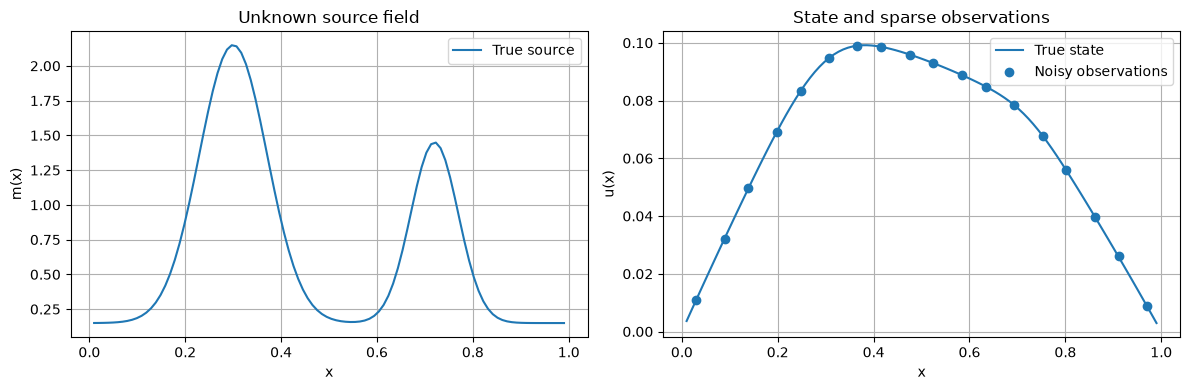

Grid points: 100
Number of observations: 18
Noise standard deviation: 5.973e-05
Expected misfit at the noise level, n*sigma^2/2: 3.211e-08


In [2]:
# Interior grid: boundary values u(0)=u(1)=0 are imposed implicitly.
N = 100
x = np.linspace(0.0, 1.0, N + 2)[1:-1]
dx = 1.0 / (N + 1)

K = sp.diags([-np.ones(N - 1), 2.0 * np.ones(N), -np.ones(N - 1)], [-1, 0, 1], format="csc") / dx**2
B = sp.identity(N, format="csc")
K_lu = splu(K)                      # factorise once, reuse for every solve

def source_truth(x):
    return (
        2.0 * np.exp(-((x - 0.30) / 0.10) ** 2)
        + 1.3 * np.exp(-((x - 0.72) / 0.07) ** 2)
        + 0.15
    )

m_true = source_truth(x)
u_true = K_lu.solve(B @ m_true)

def make_observations(n_sensors=18, noise_rel=0.002, seed=123):
    # Sparse point observations with Gaussian noise (std = noise_rel * std of clean data).
    idx = np.unique(np.linspace(2, N - 3, n_sensors).round().astype(int))
    assert len(idx) == n_sensors, "sensor locations collide; use fewer sensors"
    H = np.zeros((n_sensors, N))
    H[np.arange(n_sensors), idx] = 1.0
    sigma = noise_rel * np.std(H @ u_true)
    d = H @ u_true + np.random.default_rng(seed).normal(0.0, sigma, size=n_sensors)
    return H, idx, d, sigma

H, sensor_idx, d_obs, noise_std = make_observations()
n_sensors = len(d_obs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, m_true, label="True source")
axes[0].set_xlabel("x"); axes[0].set_ylabel("m(x)")
axes[0].set_title("Unknown source field"); axes[0].grid(True); axes[0].legend()

axes[1].plot(x, u_true, label="True state")
axes[1].scatter(x[sensor_idx], d_obs, label="Noisy observations", zorder=3)
axes[1].set_xlabel("x"); axes[1].set_ylabel("u(x)")
axes[1].set_title("State and sparse observations"); axes[1].grid(True); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Grid points: {N}")
print(f"Number of observations: {n_sensors}")
print(f"Noise standard deviation: {noise_std:.3e}")
print(f"Expected misfit at the noise level, n*sigma^2/2: {0.5 * n_sensors * noise_std**2:.3e}")

## 6. Implement the forward solve, adjoint solve and gradient

For a candidate source $m$:

1. **Forward solve:** solve $Ku=Bm$.
2. **Residual:** calculate $r=Hu-d$.
3. **Adjoint solve:** solve $K^T\lambda=H^Tr$ (we ask the factorisation for a *transposed* solve, which is what the maths requires even though $K$ is symmetric here).
4. **Gradient:** calculate $B^T\lambda+\beta L^TLm$.

The regulariser is passed in as a matrix `L`; the default $L=I$ penalises large source magnitudes but not rapid spatial oscillations. We also keep a counter of solves, which we use in Section 11.

`objective` evaluates $J$ only (one forward solve); `objective_and_gradient` also returns the adjoint gradient (one forward plus one adjoint solve). Both read the global `H` and `d_obs`.

In [3]:
solve_count = {"forward": 0, "adjoint": 0}
L_identity = sp.identity(N, format="csc")

def forward_solve(m):
    solve_count["forward"] += 1
    return K_lu.solve(B @ m)                      # K u = B m

def adjoint_solve(rhs):
    solve_count["adjoint"] += 1
    return K_lu.solve(rhs, trans="T")             # K^T lambda = rhs

def objective(m, beta=1e-7, L=None):
    L = L_identity if L is None else L
    r = H @ forward_solve(m) - d_obs
    Lm = L @ m
    return 0.5 * r @ r + 0.5 * beta * Lm @ Lm

def objective_and_gradient(m, beta=1e-7, L=None):
    L = L_identity if L is None else L
    u = forward_solve(m)
    r = H @ u - d_obs                              # residual
    Lm = L @ m
    J = 0.5 * r @ r + 0.5 * beta * Lm @ Lm

    lam = adjoint_solve(H.T @ r)                   # K^T lam = H^T r
    grad = B.T @ lam + beta * (L.T @ Lm)           # convention: Lagrangian = J - lam^T (K u - B m)
    return J, grad

J0, g0 = objective_and_gradient(np.zeros(N))
print(f"Initial objective: {J0:.6e}")
print(f"Gradient norm at m=0: {np.linalg.norm(g0):.6e}")

Initial objective: 4.647870e-02
Gradient norm at m=0: 1.303220e-02


## 7. Mandatory checkpoint: verify the adjoint gradient

A gradient can look plausible and still contain a sign or transpose error. We should verify it independently.

For a direction $v$, the directional derivative is approximated by a central difference

$$
DJ(m)[v]\approx\frac{J(m+hv)-J(m-hv)}{2h},
$$

and the adjoint predicts $DJ(m)[v]=\nabla_mJ(m)^Tv$.

We also run a **Taylor test**, which does not rely on cancellation of nearly equal numbers in the same way: if the gradient is correct, the remainder $|J(m+hv)-J(m)-h\,\nabla J^Tv|$ shrinks like $h^2$; a wrong gradient only gives $O(h)$. The second curve below is a deliberately broken gradient (adjoint term with the wrong sign) so you can see what failure looks like.

h=1.0e-01 | finite difference=+5.57350720e-04 | adjoint=+5.57350720e-04 | relative error=5.758e-14
h=1.0e-02 | finite difference=+5.57350720e-04 | adjoint=+5.57350720e-04 | relative error=1.198e-13
h=1.0e-03 | finite difference=+5.57350720e-04 | adjoint=+5.57350720e-04 | relative error=9.457e-12
h=1.0e-04 | finite difference=+5.57350720e-04 | adjoint=+5.57350720e-04 | relative error=9.014e-11
h=1.0e-05 | finite difference=+5.57350721e-04 | adjoint=+5.57350720e-04 | relative error=1.273e-09
h=1.0e-06 | finite difference=+5.57350725e-04 | adjoint=+5.57350720e-04 | relative error=7.498e-09
h=1.0e-07 | finite difference=+5.57350797e-04 | adjoint=+5.57350720e-04 | relative error=1.382e-07
h=1.0e-08 | finite difference=+5.57350693e-04 | adjoint=+5.57350720e-04 | relative error=4.853e-08


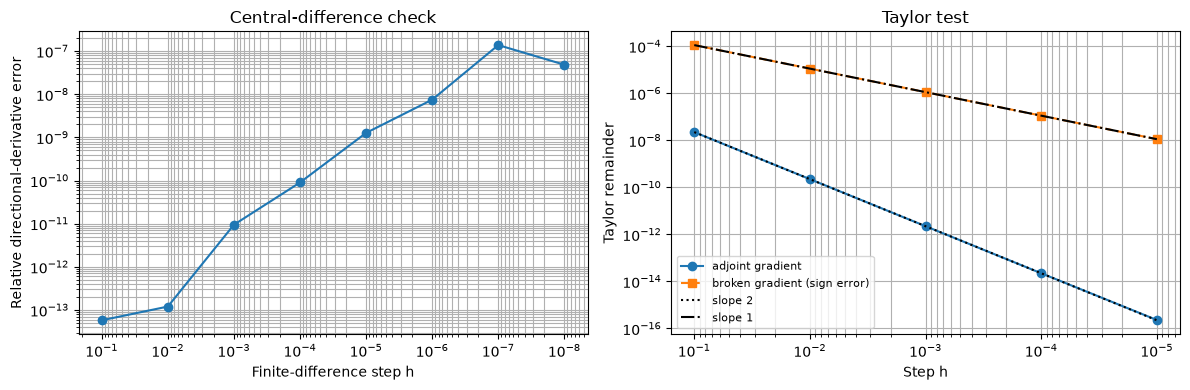

In [4]:
rng_check = np.random.default_rng(0)
m_check = 0.2 * rng_check.normal(size=N)
v_dir = rng_check.normal(size=N)
v_dir /= np.linalg.norm(v_dir)

beta_chk = 1e-7
J_check, g_check = objective_and_gradient(m_check, beta_chk)
dd_adjoint = g_check @ v_dir
g_broken = 2.0 * beta_chk * m_check - g_check        # flips the sign of the adjoint term only
dd_broken = g_broken @ v_dir

steps_fd = np.logspace(-1, -8, 8)
fd_rel_err = []
for h in steps_fd:
    Jp = objective(m_check + h * v_dir, beta_chk)
    Jm = objective(m_check - h * v_dir, beta_chk)
    fd = (Jp - Jm) / (2.0 * h)
    rel = abs(fd - dd_adjoint) / max(abs(fd), abs(dd_adjoint), 1e-300)
    fd_rel_err.append(max(rel, 1e-17))               # floor so zeros survive a log axis
    print(f"h={h:.1e} | finite difference={fd:+.8e} | adjoint={dd_adjoint:+.8e} | relative error={rel:.3e}")

steps_tay = np.logspace(-1, -5, 5)
rem_ok, rem_bad = [], []
for h in steps_tay:
    Jp = objective(m_check + h * v_dir, beta_chk)
    rem_ok.append(abs(Jp - J_check - h * dd_adjoint))
    rem_bad.append(abs(Jp - J_check - h * dd_broken))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].loglog(steps_fd, fd_rel_err, "o-")
axes[0].invert_xaxis()
axes[0].set_xlabel("Finite-difference step h"); axes[0].set_ylabel("Relative directional-derivative error")
axes[0].set_title("Central-difference check"); axes[0].grid(True, which="both")

axes[1].loglog(steps_tay, rem_ok, "o-", label="adjoint gradient")
axes[1].loglog(steps_tay, rem_bad, "s--", label="broken gradient (sign error)")
axes[1].loglog(steps_tay, rem_ok[0] * (steps_tay / steps_tay[0]) ** 2, "k:", label="slope 2")
axes[1].loglog(steps_tay, rem_bad[0] * (steps_tay / steps_tay[0]), "k-.", label="slope 1")
axes[1].invert_xaxis()
axes[1].set_xlabel("Step h"); axes[1].set_ylabel("Taylor remainder")
axes[1].set_title("Taylor test"); axes[1].grid(True, which="both"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Interpret the verification

- **This objective is exactly quadratic in $m$.** A central difference of a quadratic has *zero* truncation error, so the left plot shows only floating-point cancellation, which grows as $h$ shrinks (roughly like $\varepsilon_{\text{mach}}/h$). Agreement to ~10 digits at moderate $h$ is the signal that the adjoint is right; the rising error at tiny $h$ is rounding, not a bug.
- **Taylor test:** the correct gradient gives slope 2 (until rounding takes over at very small $h$); the sign-flipped gradient gives slope 1. This distinguishes right from wrong even when the relative errors look small.
- If your own gradient fails, inspect the residual definition, the transpose in the adjoint equation, and the sign in the gradient.

### A check with genuine truncation error: a nonlinear parameterisation

To see the classic V-shaped curve (truncation error at large $h$, rounding at small $h$) and to practise the chain rule, parameterise the source as $m=e^{q}$, which also enforces positivity. Then $J(q)$ is nonlinear and $\nabla_qJ=m\odot\nabla_mJ$.

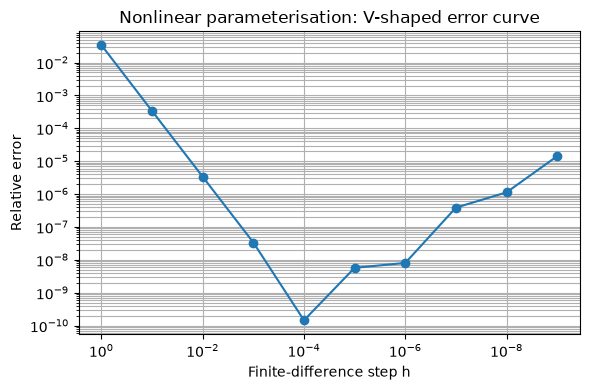

Best relative error: 1.45e-10 at h=1e-04


In [5]:
def objective_log_source(q, beta=1e-7):
    m = np.exp(q)
    J, grad_m = objective_and_gradient(m, beta)
    return J, m * grad_m                              # chain rule: dm/dq = diag(m)

q0 = np.log(0.5 + rng_check.random(N))
_, g_q = objective_log_source(q0)
dd_q = g_q @ v_dir

steps_q = np.logspace(0, -9, 10)
err_q = []
for h in steps_q:
    fd = (objective_log_source(q0 + h * v_dir)[0] - objective_log_source(q0 - h * v_dir)[0]) / (2 * h)
    err_q.append(abs(fd - dd_q) / abs(dd_q))

plt.figure(figsize=(6, 4))
plt.loglog(steps_q, err_q, "o-")
plt.gca().invert_xaxis()
plt.xlabel("Finite-difference step h"); plt.ylabel("Relative error")
plt.title("Nonlinear parameterisation: V-shaped error curve")
plt.grid(True, which="both"); plt.tight_layout(); plt.show()
print(f"Best relative error: {min(err_q):.2e} at h={steps_q[int(np.argmin(err_q))]:.0e}")

### Why a symmetric $K$ can hide a transpose bug

For the Poisson matrix, $K^T=K$, so using `trans="N"` instead of `trans="T"` in the adjoint solve gives the *same* answer and the gradient test passes. Most real PDE operators (advection, anisotropic or variable-coefficient problems, many time-stepping schemes) are not symmetric. To see the bug appear, add an advection term, $-u''+c\,u'=m$, which makes $K$ non-symmetric, and test the correct and incorrect adjoint solves.

In [6]:
c_adv = 20.0
C_adv = sp.diags([-np.ones(N - 1), np.ones(N - 1)], [-1, 1], format="csc") / (2.0 * dx)  # central d/dx
lu_adv = splu((K + c_adv * C_adv).tocsc())

def misfit_and_gradient(lu, m, wrong_transpose=False):
    # beta = 0, B = I: gradient is just lambda.
    u = lu.solve(m)
    r = H @ u - d_obs
    lam = lu.solve(H.T @ r, trans="N" if wrong_transpose else "T")
    return 0.5 * r @ r, lam

def directional_error(lu, wrong_transpose, h=1e-5):
    _, g = misfit_and_gradient(lu, m_check, wrong_transpose)
    fd = (misfit_and_gradient(lu, m_check + h * v_dir)[0]
          - misfit_and_gradient(lu, m_check - h * v_dir)[0]) / (2 * h)
    return abs(fd - g @ v_dir) / abs(fd)

for name, lu in [("symmetric K (Poisson)", K_lu), ("non-symmetric K (advection-diffusion)", lu_adv)]:
    for wrong in (False, True):
        label = "WRONG (no transpose)" if wrong else "correct (transpose)  "
        print(f"{name:40s} | {label} | relative error = {directional_error(lu, wrong):.2e}")

symmetric K (Poisson)                    | correct (transpose)   | relative error = 1.23e-09
symmetric K (Poisson)                    | WRONG (no transpose) | relative error = 1.23e-09
non-symmetric K (advection-diffusion)    | correct (transpose)   | relative error = 9.62e-09
non-symmetric K (advection-diffusion)    | WRONG (no transpose) | relative error = 2.42e+00


## 8. Reconstruct the unknown source

We now use L-BFGS-B, which accepts an objective and its gradient. The initial guess is zero.

Because observations are sparse, many source fields can produce similar observed states. Regularisation helps select a stable solution, but it does not create information that the measurements do not contain.

**Check that the optimiser has really converged.** This objective is badly scaled (the gradient is tiny and the Hessian has a very wide eigenvalue range), so SciPy's default tolerances can stop the iteration long before the minimum and an early-stopped iteration acts as an *implicit, uncontrolled* regulariser, which would silently contaminate any comparison between values of $\beta$. We therefore (i) use tight tolerances and (ii) compare against the exact Tikhonov solution obtained from the normal equations,

$$
(G^TG+\beta L^TL)\,m=G^Td,\qquad G=HK^{-1}B,
$$

which is feasible only because the problem is small and linear — it serves purely as an independent reference. Note that this check also validates the whole forward–adjoint–optimiser pipeline.

Optimisation success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Iterations: 118
Final objective: 4.109352e-06
Difference from exact Tikhonov solution: 1.41e-04  (should be << 1)
Relative source error vs truth: 7.638%


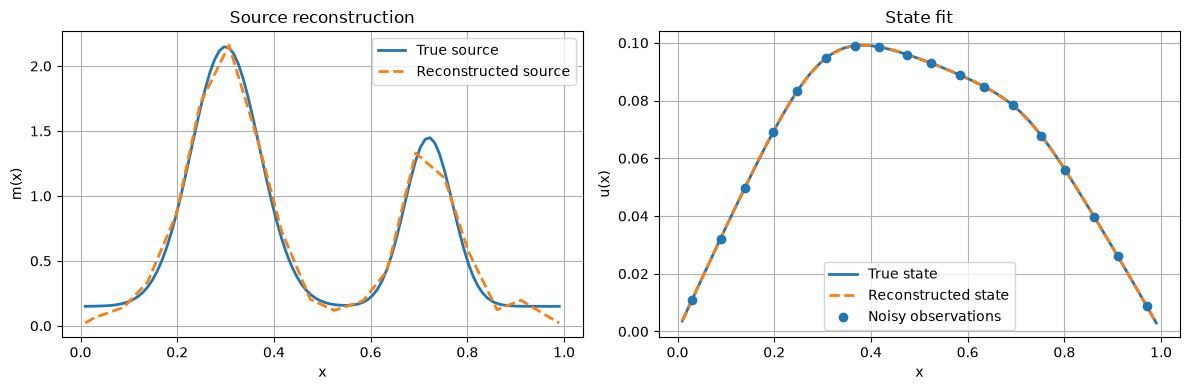

In [7]:
K_inv_B = K_lu.solve(B.toarray())                     # dense K^{-1}B; used ONLY for the reference solution

def reference_solution(beta, L=None):
    L = L_identity if L is None else L
    G = H @ K_inv_B
    return np.linalg.solve(G.T @ G + beta * (L.T @ L).toarray(), G.T @ d_obs)

def solve_inverse(beta, L=None, maxiter=20000):
    return minimize(
        fun=lambda m: objective_and_gradient(m, beta, L),
        x0=np.zeros(N), jac=True, method="L-BFGS-B",
        options={"maxiter": maxiter, "maxfun": 10 * maxiter, "ftol": 1e-15, "gtol": 1e-12},
    )

def rel_err(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)

beta = 1e-7
result = solve_inverse(beta)
m_rec = result.x
u_rec = forward_solve(m_rec)
m_ref = reference_solution(beta)

print("Optimisation success:", result.success)
print("Message:", result.message)
print("Iterations:", result.nit)
print(f"Final objective: {result.fun:.6e}")
print(f"Difference from exact Tikhonov solution: {rel_err(m_rec, m_ref):.2e}  (should be << 1)")
print(f"Relative source error vs truth: {rel_err(m_rec, m_true):.3%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, m_true, label="True source", linewidth=2)
axes[0].plot(x, m_rec, "--", label="Reconstructed source", linewidth=2)
axes[0].set_xlabel("x"); axes[0].set_ylabel("m(x)")
axes[0].set_title("Source reconstruction"); axes[0].grid(True); axes[0].legend()

axes[1].plot(x, u_true, label="True state", linewidth=2)
axes[1].plot(x, u_rec, "--", label="Reconstructed state", linewidth=2)
axes[1].scatter(x[sensor_idx], d_obs, label="Noisy observations", zorder=3)
axes[1].set_xlabel("x"); axes[1].set_ylabel("u(x)")
axes[1].set_title("State fit"); axes[1].grid(True); axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Why regularisation matters

The observation operator samples only a small part of the state, so the source is not uniquely determined by the data alone. We compare several values of $\beta$ and inspect both the data fit and the source reconstruction.

The data misfit is $J_{\mathrm{data}}=\frac12\|Hu-d\|_2^2$ and the zero-order penalty is $J_{\mathrm{reg}}=\frac{\beta}{2}\|m\|_2^2$.

A useful guide is the **discrepancy principle**: if the noise has standard deviation $\sigma$, a reasonable reconstruction should fit the data to about the noise level, i.e. $J_{\mathrm{data}}\approx n\sigma^2/2$. A misfit far *below* that means the model is fitting noise; far *above* means it is over-smoothed. The dashed line in the right-hand plot marks this target. (In real problems $\sigma$ is rarely known exactly, so treat it as a guide, not a rule.)

All runs below use tight tolerances and are checked against the exact reference solution.

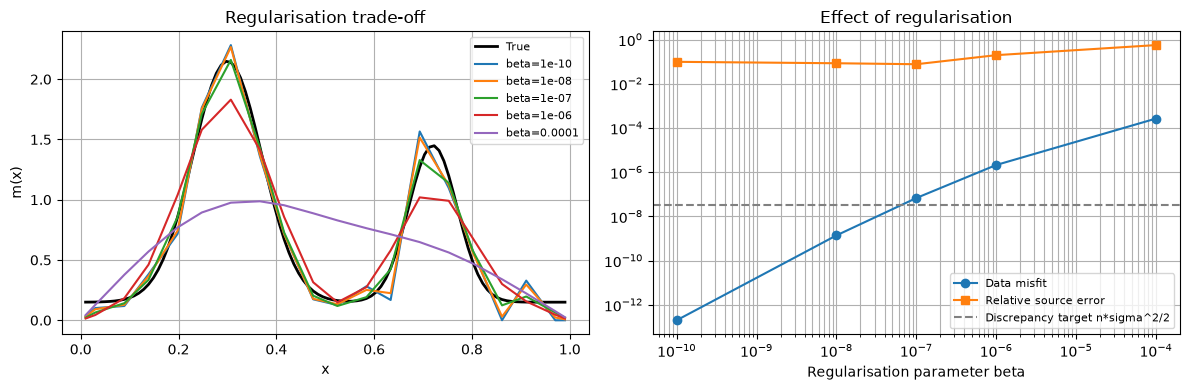

Discrepancy target for the misfit: 3.211e-08
beta= 1.0e-10 | data misfit=1.9880e-13 | relative source error= 9.81% | gap to exact solution=7.4e-05
beta= 1.0e-08 | data misfit=1.3766e-09 | relative source error= 8.46% | gap to exact solution=3.9e-04
beta= 1.0e-07 | data misfit=6.7624e-08 | relative source error= 7.64% | gap to exact solution=1.4e-04
beta= 1.0e-06 | data misfit=2.1102e-06 | relative source error=19.63% | gap to exact solution=8.2e-06
beta= 1.0e-04 | data misfit=2.6613e-04 | relative source error=56.02% | gap to exact solution=6.6e-10


In [8]:
beta_values = [1e-10, 1e-8, 1e-7, 1e-6, 1e-4]
solutions, data_misfits, source_errors, ref_gaps = [], [], [], []

for b in beta_values:
    res = solve_inverse(b)
    solutions.append(res.x)
    u_b = forward_solve(res.x)
    data_misfits.append(0.5 * np.linalg.norm(H @ u_b - d_obs) ** 2)
    source_errors.append(rel_err(res.x, m_true))
    ref_gaps.append(rel_err(res.x, reference_solution(b)))

target = 0.5 * n_sensors * noise_std ** 2

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, m_true, "k", linewidth=2, label="True")
for b, m_b in zip(beta_values, solutions):
    axes[0].plot(x, m_b, label=f"beta={b:g}")
axes[0].set_xlabel("x"); axes[0].set_ylabel("m(x)")
axes[0].set_title("Regularisation trade-off"); axes[0].grid(True); axes[0].legend(fontsize=8)

axes[1].loglog(beta_values, data_misfits, "o-", label="Data misfit")
axes[1].loglog(beta_values, source_errors, "s-", label="Relative source error")
axes[1].axhline(target, color="gray", linestyle="--", label="Discrepancy target n*sigma^2/2")
axes[1].set_xlabel("Regularisation parameter beta")
axes[1].set_title("Effect of regularisation"); axes[1].grid(True, which="both"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Discrepancy target for the misfit: {target:.3e}")
for b, misfit, err, gap in zip(beta_values, data_misfits, source_errors, ref_gaps):
    print(f"beta={b:8.1e} | data misfit={misfit:.4e} | relative source error={err:6.2%} | gap to exact solution={gap:.1e}")

**Reading the results.** The data misfit increases monotonically with $\beta$ (more regularisation, worse fit). The source error is U-shaped: it is smallest for a moderate $\beta$ whose misfit is close to the discrepancy target, and grows quickly once $\beta$ is large enough to shrink the solution towards zero. On the small-$\beta$ side the error rises only gently here, because starting from $m=0$ and a smooth truth, the minimum-norm solution is already fairly benign at this low noise level. Exercise 3 (larger noise) makes the small-$\beta$ penalty much more visible.

## 10. Extension: smoothness regularisation

Zero-order Tikhonov regularisation penalises the magnitude of $m$. If the physical source is expected to vary smoothly, a first-difference penalty may be more appropriate:

$$
J_{\mathrm{reg}}(m)=\frac{\beta}{2}\|Dm\|_2^2,
$$

where $D$ is a discrete first-derivative operator (including the $1/\Delta x$ factor). Its gradient contribution is $\beta D^TDm$, which our `objective_and_gradient` already supports through the argument `L=D`,  no new gradient code is needed.

**Caution:** $\beta$ values are *not comparable* across different penalties. Because $D$ contains $1/\Delta x\approx 100$, $\|Dm\|^2$ is orders of magnitude larger than $\|m\|^2$ for the same field, so the best smoothness $\beta$ is much smaller than the best zero-order $\beta$. Always re-tune $\beta$ for each penalty.

beta_smooth= 1.0e-12 | data misfit=5.914e-11 | relative source error= 8.77%
beta_smooth= 1.0e-11 | data misfit=2.522e-09 | relative source error= 6.11%
beta_smooth= 1.0e-10 | data misfit=3.613e-08 | relative source error= 5.34%
beta_smooth= 1.0e-09 | data misfit=3.855e-07 | relative source error=14.76%
beta_smooth= 1.0e-08 | data misfit=6.485e-06 | relative source error=28.00%

Selected beta_smooth=1e-10 (misfit closest to target 3.21e-08)


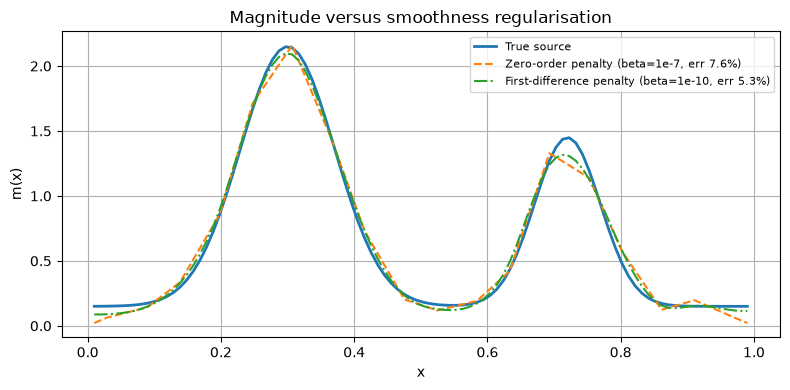

In [9]:
# First-difference operator, (N-1) x N; boundary rows omitted for simplicity.
D = sp.diags([-np.ones(N - 1), np.ones(N - 1)], [0, 1], shape=(N - 1, N), format="csc") / dx

beta_smooth_values = [1e-12, 1e-11, 1e-10, 1e-9, 1e-8]
smooth_sols, smooth_err, smooth_misfit = [], [], []
for b in beta_smooth_values:
    res = solve_inverse(b, L=D)
    smooth_sols.append(res.x)
    smooth_err.append(rel_err(res.x, m_true))
    smooth_misfit.append(0.5 * np.linalg.norm(H @ forward_solve(res.x) - d_obs) ** 2)
    assert rel_err(res.x, reference_solution(b, D)) < 1e-2   # optimiser agrees with the exact solution

for b, e, mf in zip(beta_smooth_values, smooth_err, smooth_misfit):
    print(f"beta_smooth={b:8.1e} | data misfit={mf:.3e} | relative source error={e:6.2%}")

# Choose the beta whose misfit is closest to the discrepancy target
best = int(np.argmin([abs(np.log(mf / target)) for mf in smooth_misfit]))
m_smooth = smooth_sols[best]
print(f"\nSelected beta_smooth={beta_smooth_values[best]:.0e} (misfit closest to target {target:.2e})")

plt.figure(figsize=(8, 4))
plt.plot(x, m_true, label="True source", linewidth=2)
plt.plot(x, m_rec, "--", label=f"Zero-order penalty (beta=1e-7, err {rel_err(m_rec, m_true):.1%})")
plt.plot(x, m_smooth, "-.", label=f"First-difference penalty (beta={beta_smooth_values[best]:.0e}, err {smooth_err[best]:.1%})")
plt.xlabel("x"); plt.ylabel("m(x)")
plt.title("Magnitude versus smoothness regularisation")
plt.grid(True); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 11. Computational scaling: finite differences versus an adjoint

For $N$ unknowns, a forward finite-difference gradient needs $N+1$ objective evaluations and a central-difference gradient needs $2N$. The adjoint gradient needs one forward and one adjoint solve. This is a count of major solves, not a universal wall-clock speedup: in real applications, linear-solver cost, preconditioning, parallelism, and whether factorisations can be reused all matter. Here the solve counts are *measured* by the counters in `forward_solve` and `adjoint_solve`, and we also confirm that all three gradients agree.

In [10]:
def fd_gradient(fun, m, h=1e-6, scheme="central"):
    g = np.zeros_like(m)
    f0 = fun(m) if scheme == "forward" else None
    for i in range(m.size):
        e = np.zeros_like(m); e[i] = 1.0
        if scheme == "central":
            g[i] = (fun(m + h * e) - fun(m - h * e)) / (2 * h)
        else:
            g[i] = (fun(m + h * e) - f0) / h
    return g

m_scale = 0.2 * np.random.default_rng(1).normal(size=N)
beta_s = 1e-7

results = {}
for scheme, h in [("forward", 1e-7), ("central", 1e-5)]:
    solve_count.update(forward=0, adjoint=0)
    g = fd_gradient(lambda m: objective(m, beta_s), m_scale, h=h, scheme=scheme)
    results[f"FD ({scheme})"] = (g, dict(solve_count))

solve_count.update(forward=0, adjoint=0)
_, g_adj = objective_and_gradient(m_scale, beta_s)
results["Adjoint"] = (g_adj, dict(solve_count))

print(f"Unknown parameters N = {N}\n")
for name, (g, cnt) in results.items():
    print(f"{name:14s}: {cnt['forward']:4d} forward + {cnt['adjoint']} adjoint solves | "
          f"relative difference from adjoint gradient = {rel_err(g, g_adj):.1e}")

Unknown parameters N = 100

FD (forward)  :  101 forward + 0 adjoint solves | relative difference from adjoint gradient = 5.4e-08
FD (central)  :  200 forward + 0 adjoint solves | relative difference from adjoint gradient = 2.4e-10
Adjoint       :    1 forward + 1 adjoint solves | relative difference from adjoint gradient = 0.0e+00


## 12. Connection to experiments, 4D-Var and CFD

The same structure appears in many scientific inverse problems:

- **Thermal experiments:** infer a heat-source distribution or thermal parameters from sparse temperature measurements.
- **4D-Var:** minimise observation mismatch over a time window by integrating the model forward and solving a time-dependent adjoint problem backward.
- **CFD optimisation:** compute sensitivities of drag, lift or other objectives to shape, boundary conditions or model parameters.
- **PINNs and automatic differentiation:** compare gradients through a parameterised neural network with gradients obtained by differentiating or adjointing a numerical PDE solver. These approaches can be combined (e.g. reverse-mode AD *is* a discrete adjoint), but they are not interchangeable in every setting.

### Important distinction

A **discrete adjoint** is derived from the discretised equations (what we did here). A **continuous adjoint** is derived from the continuous PDE and then discretised. For some discretisations they agree closely; for others, their boundary conditions and numerical details can differ ("optimise-then-discretise" versus "discretise-then-optimise"). Production CFD adjoints require careful verification.

## 13. Exercises

### Exercise 1: Gradient verification
Change the random direction (and the point `m_check`) and repeat the directional-derivative and Taylor tests. Explain why extremely small finite-difference steps worsen the agreement even though the objective is exactly quadratic.

### Exercise 2: Sensor placement
Call `H, sensor_idx, d_obs, noise_std = make_observations(n_sensors=...)` with 8, 18 and 40 sensors, re-run Sections 8–9 and compare the relative source error. Does increasing the number of sensors always improve the reconstruction for this particular noise realisation? Try a few `seed` values.

### Exercise 3: Noise sensitivity
Use `make_observations(noise_rel=0.01)` (five times more noise). Compare reconstructions at several regularisation strengths and check the discrepancy-principle target. How does the best $\beta$ move?

### Exercise 4: Smoothness prior
Change the first-difference regularisation strength. Explain how the penalty changes the source field and why it may be appropriate for some physical fields but inappropriate for discontinuous sources (try a piecewise-constant `source_truth`).

### Exercise 5: Different observation operator
Replace point sampling with an observation operator that averages neighbouring state values. Explain how the adjoint maps the residual back into the state space (what is $H^T$ now?), and re-run the gradient check.

### Exercise 6: Non-symmetric operator
Using `lu_adv` from Section 7, build the full inverse problem (objective, gradient, L-BFGS-B) for the advection–diffusion equation. Which line of the code would silently break if you forgot the transpose?

### Exercise 7: Research extension
Write down the forward, adjoint and gradient equations for a transient heat equation. Identify which variables and boundary/terminal conditions you need to derive the time-dependent adjoint correctly.

### Suggested discussion prompts

1. Why does the number of adjoint solves usually not scale with the number of scalar parameters?
2. What information is lost when measurements are sparse?
3. What does regularisation contribute, and what can it not guarantee?
4. Why can an under-converged optimiser look like a regulariser, and how would you detect it?
5. What extra complications arise for nonlinear PDEs?

## 14. Take-home summary

- PDE-constrained inverse problems combine a governing equation with an observation-mismatch objective.
- The Lagrangian introduces an adjoint variable that eliminates the need to differentiate the state explicitly with respect to every parameter.
- The adjoint gradient must be verified, preferably with directional finite differences *and* a Taylor test; remember that symmetric operators can hide transpose errors.
- Check optimiser convergence (tight tolerances, comparison with a reference when one exists) before interpreting any regularisation study.
- Efficient gradients do not solve identifiability problems: measurement design and regularisation remain essential, and $\beta$ must be tuned per penalty.
- The discrete Poisson example is a stepping stone toward time-dependent 4D-Var, inverse heat transfer, and adjoint-enabled CFD.

**Next tutorial:** Application of adjoint to PIV dataset.